# What is a Classification Problem?

In machine learning, a **classification problem** involves predicting which category or label an input belongs to. 

Instead of predicting a continuous number (like predicting house prices or temperature), you are sorting things into predefined buckets.

---

### Main Types of Classification

| Problem Type | What is it? | Real-World Example |
| :--- | :--- | :--- |
| **Binary Classification** | The target can only be **one of two options** (e.g., Yes/No, True/False). | Predict whether a patient **has heart disease** or **does not** based on medical tests. |
| **Multi-Class Classification** | The target can be **one out of three or more options**, but *only one* can be chosen. | Classify a photo as either a **dog**, a **cat**, or a **car**. |
| **Multi-Label Classification** | The target can be assigned **more than one option** at the same time. | Tag a blog post or Wikipedia article with multiple topics (e.g., **"Science"**, **"History"**, and **"Education"**). |

---

### Key Takeaway
* **Binary:** Pick 1 out of 2.
* **Multi-Class:** Pick 1 out of many.
* **Multi-Label:** Pick multiple out of many.

# PyTorch Classification: Module Overview

Instead of predicting a continuous number along a straight line (a **regression problem**), we focus on predicting categories (a **classification problem**). 

Here is what we will cover across this workflow:

---

| # | Topic | What We Cover |
| :-: | :--- | :--- |
| **0** | **Architecture of a Classification Network** | The standard "floor plan" of classification models: input layers, hidden layers, activation functions, and output shapes. |
| **1** | **Getting Binary Classification Data Ready** | Generating and preparing a simple 2-class toy dataset (e.g., circles or moons) into PyTorch tensors. |
| **2** | **Building a PyTorch Classification Model** | Defining the neural network subclass, setting the loss function (`nn.BCEWithLogitsLoss`), and choosing an optimizer (e.g., `SGD` or `Adam`). |
| **3** | **Fitting the Model to Data (Training)** | Building the classification training loop: forward pass, loss calculation, zeroing gradients, backpropagation, and optimizer step. |
| **4** | **Making Predictions & Evaluation (Inference)** | Converting raw model outputs (**logits**) $\rightarrow$ **probabilities** $\rightarrow$ **prediction labels**, then evaluating accuracy on unseen test data. |
| **5** | **Improving a Model** | Experimenting with hyperparameters: adding hidden units, increasing layers, adjusting learning rates, or training for more epochs. |
| **6** | **The Need for Non-Linearity** | Seeing why purely linear models fail on circular or curved decision boundaries (the straight-line limitation). |
| **7** | **Replicating Non-Linear Functions** | Deconstructing and visually exploring common activation functions like **ReLU** and **Sigmoid** from scratch. |
| **8** | **Putting It All Together: Multi-Class Classification** | Scaling from binary to multi-class classification using **Cross-Entropy Loss** and the **Softmax** function. |

---

### Key Workflow Progression
$$\text{Data Prep} \longrightarrow \text{Model Architecture} \longrightarrow \text{Training Loop} \longrightarrow \text{Non-Linear Activations} \longrightarrow \text{Multi-Class Scaling}$$

# 0. Architecture of a Classification Neural Network

Before writing code, here is the standard architectural blueprint comparing **Binary Classification** and **Multiclass Classification** models:

---

| Hyperparameter / Component | Binary Classification | Multiclass Classification |
| :--- | :--- | :--- |
| **Input layer shape (`in_features`)** | Same as number of features (e.g., $5$ for age, sex, height, weight, smoking status) | Same as binary classification |
| **Hidden layer(s)** | Problem-specific, minimum = $1$, maximum = unlimited | Problem-specific, minimum = $1$, maximum = unlimited |
| **Neurons per hidden layer** | Problem-specific, generally $10$ to $512$ | Problem-specific, generally $10$ to $512$ |
| **Output layer shape (`out_features`)** | **$1$** (predicts probability of the positive class) | **$1$ per class** (e.g., $3$ for `[food, person, dog]`) |
| **Hidden layer activation** | Usually **ReLU** (`torch.nn.ReLU`), or LeakyReLU, GELU | Same as binary classification |
| **Output activation** | **Sigmoid** (`torch.sigmoid`) | **Softmax** (`torch.softmax`) |
| **Loss function** | Binary Cross-Entropy (`nn.BCELoss` or `nn.BCEWithLogitsLoss`) | Categorical Cross-Entropy (`nn.CrossEntropyLoss`) |
| **Optimizer** | `torch.optim.SGD`, `torch.optim.Adam`, etc. | Same as binary classification |

---

### Key Structural Differences at a Glance

* **Binary Classification:**
  * Outputs a single scalar value per sample (raw value called a **logit**).
  * Passes through a **Sigmoid** activation to squash the output between $0$ and $1$ (representing probability $P(Y = 1)$).
* **Multiclass Classification:**
  * Outputs an array of $C$ numbers per sample (where $C$ is the total class count).
  * Passes through a **Softmax** activation so all values sum to $1.0$, creating a discrete probability distribution over all classes.

# 1. Make classification data and get it ready

In [1]:
from sklearn.datasets import make_circles 

# Make 1000 samples 
n_samples = 1000

# creates circles 
X,y = make_circles(n_samples,noise = 0.03,random_state = 42 )

# noise = 0.03 ,a little of noise to the dots 
# random_state = 42 ,  keep random state so we get the same values 

In [2]:
print(f"First 5 X features:\n{X[:5]}")
print(f"\nFirst 5 y labels:\n{y[:5]}")

First 5 X features:
[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]

First 5 y labels:
[1 1 1 1 0]


In [3]:
## Make DataFrame of circles data 
import pandas as pd 
circles = pd.DataFrame({"X1": X[:,0],
"X2":X[:,1], # 500 for class 0, 500 for class 1.
"label":y})
circles.head(10)


,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


In [4]:
## Check different labels 

circles.label.value_counts() # 500 for class 0, 500 for class 1.


label
1    500
0    500
Name: count, dtype: int64

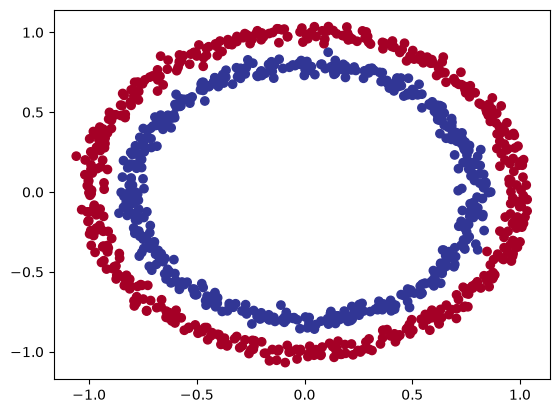

In [5]:
# visualize with plot 
import matplotlib.pyplot as plt 
plt.scatter(x=X[:,0],y=X[:,1],c=y,cmap=plt.cm.RdYlBu);

In [6]:
X.shape,y.shape # X.shape = (1000, 2) means the network must take in 2 features (in_features=2).
                # y.shape = (1000,) means each sample has 1 scalar target.

((1000, 2), (1000,))

In [7]:
# Converting to PyTorch Tensors
import torch 
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [8]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split 
X_train , X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42 )

len(X_train),len(X_test),len(y_train),len(y_test)

(800, 200, 800, 200)

# 2. Building a model

#### # We've got some data ready, now it's time to build a model

In [9]:
# standard PyTorch import 
import torch 
from torch import nn 

# DEVICE SETUP

# Make device agnostic code 
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device : {device}")


Using device : mps


In [10]:
# 1. Construct a model class that subclasses nn.module 
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()

        # 2). create 2 nn.linear layers capables of handling X and y input and output shapes 
        self.layer_1 = nn.Linear(in_features=2, out_features = 4) # # takes in 2 features (X), produces 4 features
        self.layer_2 = nn.Linear(in_features = 4 , out_features = 1) # takes in 4 features, produces 1 feature (y)

        # 3). Define a forward method containing the forward pass computations 
        def forward(self,x):
            # Return the output of layer_2, a single feature, the same shape as y
            return self.layer_2(self.layer_1(x)) # computation goes through layer_1 first then the output of layer_1 goes through layer_2
        

        # 4. Create an instance of the model and send it to target device

        model_0 = CircleModelV0().to(device)
        print(model_0)


    

In [11]:
# Replicate CircleModelV0 with nn.Sequential
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=4),
    nn.Linear(in_features=4, out_features=1)
).to(device)

model_0

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): Linear(in_features=4, out_features=1, bias=True)
)

In [12]:
# Make predictions with the model
untrained_preds = model_0(X_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[0.0907],
        [0.0548],
        [0.1609],
        [0.0709],
        [0.1233],
        [0.1017],
        [0.0306],
        [0.0415],
        [0.1624],
        [0.0520]], device='mps:0', grad_fn=<SliceBackward0>)

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


### 2.1 Setup loss function and optimizer

In [13]:
# Create a loss function
# loss_fn = nn.BCELoss() # BCELoss = no sigmoid built-in
loss_fn = nn.BCEWithLogitsLoss() # BCEWithLogitsLoss = sigmoid built-in

# Create an optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(),lr=0.1)

In [14]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() # torch.eq() calculates where two tensors are equal
    acc = (correct / len(y_pred)) * 100 
    return acc

# 3). Train Model 

### PyTorch training loop steps
* 1. Forward pass - The model goes through all of the training data once, performing its forward() function calculations (model(x_train)).
* 2. Calculate the loss - The model's outputs (predictions) are compared to the ground truth and evaluated to see how wrong they are (loss = loss_fn(y_pred, y_train).
* 3. Zero gradients - The optimizers gradients are set to zero (they are accumulated by default) so they can be recalculated for the specific training step (optimizer.zero_grad()).
* 4. Perform backpropagation on the loss - Computes the gradient of the loss with respect for every model parameter to be updated (each parameter with requires_grad=True). This is known as backpropagation, hence "backwards" (loss.backward()).
* 5. Step the optimizer (gradient descent) - Update the parameters with requires_grad=True with respect to the loss gradients in order to improve them (optimizer.step()).

## Wihout traning the model 

In [15]:
y_logits = model_0(X_test.to(device))[:5] # # View the frist 5 outputs of the forward pass on the test data
y_logits

tensor([[0.0907],
        [0.0548],
        [0.1609],
        [0.0709],
        [0.1233]], device='mps:0', grad_fn=<SliceBackward0>)

$$y = x \cdot \text{Weights}^T + \text{bias}$$
* **Logits ($y$):** The raw, unscaled linear outputs directly produced by this equation before passing through any activation function[cite: 1].
* **Inputs & Parameters:**
  * $x$: Input feature vector.
  * $\text{Weights}^T$: Transposed weight matrix mapping inputs to output dimensions.
  * $\text{bias}$: Offset value added to shift the boundary.
* **Role in Classification:** The values in vector $y$ are the logits; they can be any real numbers (positive, negative, or zero) and are typically passed to **Softmax** or **Sigmoid** to convert them into probabilities.


| Step | Stage | Values / Range | Operation / PyTorch Function |
| :---: | :--- | :--- | :--- |
| **1** | **Raw Logits** | $(-\infty, +\infty)$ | Output of linear layer ($y = x \cdot W^T + b$) |
| | $\big\downarrow$ | | *Pass through `torch.sigmoid()`* |
| **2** | **Prediction Probabilities** | $[0.0, 1.0]$ | Converts raw logits to continuous probabilities |
| | $\big\downarrow$ | | *Apply `torch.round()` (threshold at $0.5$)* |
| **3** | **Prediction Labels** | $\{0, 1\}$ | Discrete binary classification classes |

In [16]:
y_pred_probs = torch.sigmoid(y_logits) # Prediction Probabilities
y_pred_probs

tensor([[0.5227],
        [0.5137],
        [0.5401],
        [0.5177],
        [0.5308]], device='mps:0', grad_fn=<SigmoidBackward0>)

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

In [17]:
y_preds = torch.round(y_pred_probs)
y_preds

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.]], device='mps:0', grad_fn=<RoundBackward0>)

Probability $\ge 0.5 \implies$ Class 1   Probability $< 0.5 \implies$ Class 0

In [18]:
y_test[:5]  # actual test labels

tensor([1., 0., 1., 0., 1.])

### 3.2 Building a training and testing loop

### With Model Training 

In [19]:
torch.manual_seed(19)

# set the number of epochs 
epochs = 100

# put the data to target device (Neural network models and data tensors must live on the same hardware device.)
X_train,y_train = X_train.to(device),y_train.to(device)
X_test,y_test = X_test.to(device),y_test.to(device)

# Building a training evalution loop

for epochs in range(epochs):

    ## Training 
    model_0.train() # Calling train() ensures all layers act according to training specifications.
                    # model_0(X_train) produces an output of shape [800, 1] 

    # 1). Forward pass 
    # because the final layer has out_features=1,
    y_logits = model_0(X_train).squeeze() #  .squeeze() strips out any dimension of size 1, transforming [800, 1] into [800] so both shapes match cleanly.
    y_preds = torch.round(torch.sigmoid(y_logits)) # compresses logits into prediction probabilities between 0.0 and 1.0
    

    # 2). Calculate loss/accuracy 
    loss = loss_fn(y_logits,y_train) # Crucial detail: Notice it takes y_logits directly, NOT y_pred or y_pred_probs, Because BCEWithLogitsLoss has the Sigmoid activation mathematically
                                     # integrated into its loss equation, passing raw logits prevents precision errors and gradient saturation.

    acc = accuracy_fn(y_true= y_train,y_pred=y_preds) # Takes y_pred (the rounded 0 or 1 predictions) and compares them with y_train



    # 3). optimizer zero grad 
    optimizer.zero_grad() # In PyTorch, tensor gradients are accumulated (added together) during every .backward() call by default.
    # Calling .zero_grad() resets the .grad attribute of every weight and bias parameter back to zero before calculating the new epoch's derivatives.


    # 4). Loss backwards (This triggers PyTorch’s Autograd engine.)
    loss.backward() 

    # 5). optimizer step 
    optimizer.step() # This single line is where learning occurs; all weights are adjusted to produce a lower loss on the next forward pass.



    #### Testing 

    model_0.eval() # Sets the model to evaluation mode (self.training = False), disabling dropout and freezing running statistics.
    with torch.inference_mode(): # Autograd stops constructing the dynamic computation graph and stops storing intermediate activations.(to speed up)

        # 1). Forward pass 
        test_logits = model_0(X_test).squeeze() #Evaluates the updated network on the 200 unseen holdout samples (X_test, y_test) 
                                                #to verify whether changes improved generalized performance.
        test_pred = torch.round(torch.sigmoid(test_logits))
        # No loss.backward() or optimizer.step() is called here because we do not train on test data.

        # 2). calculate loss/accuracy 
        test_loss = loss_fn(test_logits,y_test)
        test_acc = accuracy_fn(y_true=y_test,y_pred=test_pred)



    # Print out what happening every 10 epochs 

    if epochs % 10 == 0 : # Uses the modulo operator (% 10 == 0) to print results every 10 iterations (0, 10, 20, ..., 90) rather than flooding the console with 100 lines.
        print(f"Epoch : {epochs} | Loss : {loss:.5f} , Accuracy : {acc : .2f} ,  Test Loss : {test_loss:.5f}")    



Epoch : 0 | Loss : 0.69527 , Accuracy :  50.00 ,  Test Loss : 0.69297
Epoch : 10 | Loss : 0.69434 , Accuracy :  58.38 ,  Test Loss : 0.69231
Epoch : 20 | Loss : 0.69398 , Accuracy :  53.00 ,  Test Loss : 0.69214
Epoch : 30 | Loss : 0.69382 , Accuracy :  51.62 ,  Test Loss : 0.69212
Epoch : 40 | Loss : 0.69372 , Accuracy :  51.12 ,  Test Loss : 0.69215
Epoch : 50 | Loss : 0.69365 , Accuracy :  50.38 ,  Test Loss : 0.69219
Epoch : 60 | Loss : 0.69359 , Accuracy :  50.62 ,  Test Loss : 0.69224
Epoch : 70 | Loss : 0.69354 , Accuracy :  50.25 ,  Test Loss : 0.69229
Epoch : 80 | Loss : 0.69350 , Accuracy :  50.38 ,  Test Loss : 0.69235
Epoch : 90 | Loss : 0.69346 , Accuracy :  50.50 ,  Test Loss : 0.69240


# 4. Make predictions and evaluate the model

* we trained model_0 for 100 epochs, but its accuracy stayed at ~50% and its loss remained stuck at ~0.693
* Because the dataset has two balanced classes, 50% accuracy means our network was essentially guessing at random.


In [20]:
# Downloading the Plotting Helper
import requests
from pathlib import Path

# Downloading helper functions from Learn PyTorch repo.
if Path("helper_functions.py").is_file():
    print("helper_fuctions.py already exists , skipping download ")
else :
    print("Download helper_functions.py")
    request =  requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")   

    with open("helper_functions.py","wb") as f :
        f.write(request.content)


from helper_functions import plot_predictions , plot_decision_boundary

helper_fuctions.py already exists , skipping download 


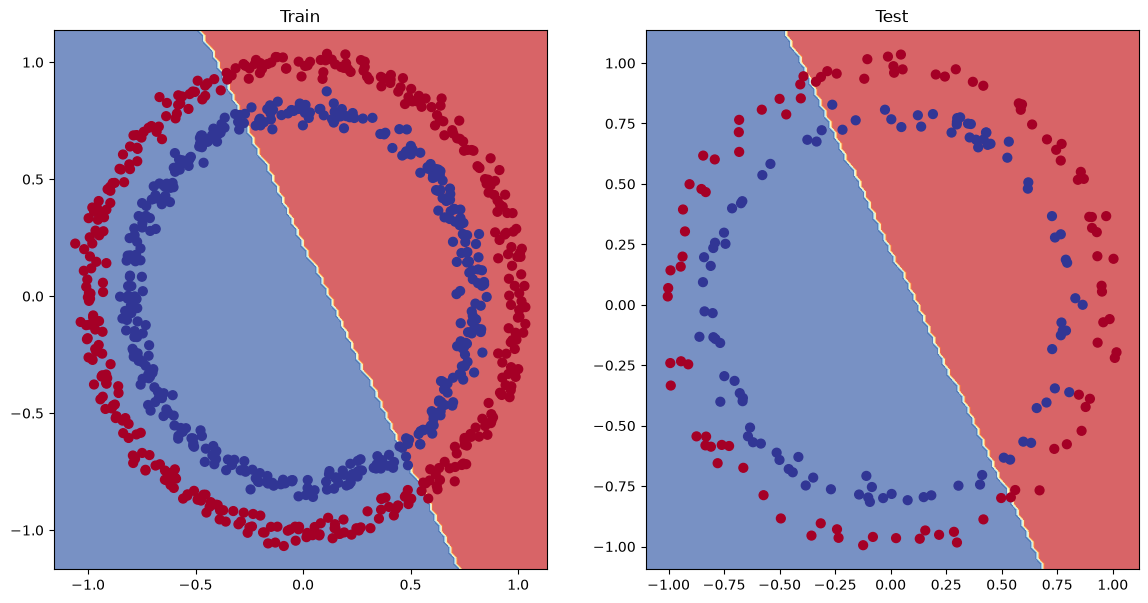

In [21]:
# Plot decision boundaries for training and test sets 
plt.figure(figsize=(14,7))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0,X_test,y_test)

### Key Takeaway: Section 4 — Make Predictions and Evaluate the Model

* **The Training Loop Worked:** The forward pass, loss calculation, backpropagation, and optimizer steps ran properly without code bugs
* **The Mathematical Constraint:** The model relied entirely on linear layers (`nn.Linear`), which compute $y = xW^T + b$. In 2D space, this equation can only represent a **single straight line**.
* **The Geometric Conflict:** Concentric circular classes require an enclosed boundary. A straight line can only bisect the circle down the middle.
* **Why Accuracy Was ~50%:** With 500 red and 500 blue points, slicing the circles in half captures roughly half of each class, capping accuracy near **50%** (the same rate as random guessing).
* **Verdict (Underfitting):** The model suffered from **underfitting**—it was too simple for circular data. To draw curved boundaries, the network requires **non-linear activation functions**.

# 5. Improving a model (from a model perspective)

### Summary Checklist: Standard Strategies to Improve a Model (Fixing Underfitting)

| # | Hyperparameter / Strategy | Mechanism | What It Solves |
| :-: | :--- | :--- | :--- |
| **1** | **Add more layers (Deeper network)** | Increases hierarchical representation capacity; enables the network to learn higher-level combinations of patterns. | Inability to capture complex, multi-stage relationships. |
| **2** | **Add hidden units (Wider network)** | Increases feature extraction capacity per layer; allows simultaneous evaluation of multiple input signals. | Limited expressiveness or bottlenecking at specific layers. |
| **3** | **Increase epochs (Train longer)** | Provides the optimizer with more update steps to push weights toward a lower loss value. | Premature stopping before convergence (gradient descent under-trained). |
| **4** | **Introduce / change activation functions** | Injects non-linearity (e.g., ReLU instead of pure linear layers) so the model can construct non-linear decision boundaries. | Linear underfitting (unable to fit curved data patterns). |
| **5** | **Tune the learning rate ($\alpha$)** | Calibrates step size: prevents tiny progress (too small) or oscillations/overshooting (too large). | Stagnant loss reduction or failure to reach the global/local minimum. |
| **6** | **Adjust loss function / Leverage transfer learning** | Aligns optimization targets properly or initializes weights from a pre-trained feature extractor. | Mismatched error metrics or limited training data for training from scratch. |

In [22]:
# 1).Let's see what happens if we add an extra layer to our model, fit for longer (epochs=1000 instead of epochs=100) 
# and increase the number of hidden units from 5 to 10.
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(in_features=2,out_features=10)
        self.layer2 = nn.Linear(in_features=10,out_features=10) # Adding an extra layer
        self.layer3 = nn.Linear(in_features=10,out_features=1)

        ## OR we can also do that as , 
    #.  Z = self.layer1(x)
    #   Z = self.layer2(y)
    #   Z = self.layer3(z)
    #   return Z  

    def forward(self,x):
        return self.layer3(self.layer2(self.layer1(x)))    

model_1 = CircleModelV1().to(device)
model_1
    


CircleModelV1(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
)

### Now we've got a model, we'll recreate a loss function and optimizer instance, using the same settings as before

In [23]:
loss_fn = nn.BCEWithLogitsLoss() # have a sigmoid itself 
optimizer = torch.optim.SGD(model_1.parameters(),lr = 0.1)



#### model, optimizer and loss function ready, let's make a training loop.

#### This time we'll train for longer (epochs=1000 vs epochs=100) and see if it improves our model.

In [24]:
torch.manual_seed(19)
epochs = 1000

# Put Data into same device 
X_test , y_test = X_test.to(device),y_test.to(device)
X_train,y_train = X_train.to(device),y_train.to(device)

for epochs in range(epochs):

    ##### Training 

    # 1). Forward pass 
    y_logits = model_1(X_train).squeeze()
    y_preds = torch.round(torch.sigmoid(y_logits)) # logits -> prediction probabilities -> prediction labels

    # 2). Calculating loss/accuracy 
    Loss = loss_fn(y_logits,y_train)
    acc = accuracy_fn(y_true=y_train,y_pred=y_preds)

    # 3). Optimizer step
    optimizer.zero_grad()

    # 4). Loss Backwards 
    Loss.backward()

    # 5). Optimizer step 
    optimizer.step()


    ##### TESTING 
    model_1.eval()
    with torch.inference_mode():

        # 1). Forward Pass 
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        # Calculate accuracy/ Loss
        test_loss = loss_fn(test_logits,y_test)
        test_acc = accuracy_fn(y_true=y_test,y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epochs % 100 == 0 :
        print(f"EPOCHS : {epochs} | Loss : {loss:.5f}, Accuracy : {acc:.2f} | Test loss : {test_loss:.5f} ,  Test Accuracy : {test_acc : .2f}%" )   



EPOCHS : 0 | Loss : 0.69343, Accuracy : 50.00 | Test loss : 0.69336 ,  Test Accuracy :  50.00%
EPOCHS : 100 | Loss : 0.69343, Accuracy : 50.25 | Test loss : 0.69274 ,  Test Accuracy :  52.00%
EPOCHS : 200 | Loss : 0.69343, Accuracy : 50.75 | Test loss : 0.69379 ,  Test Accuracy :  47.50%
EPOCHS : 300 | Loss : 0.69343, Accuracy : 51.38 | Test loss : 0.69428 ,  Test Accuracy :  46.00%
EPOCHS : 400 | Loss : 0.69343, Accuracy : 51.62 | Test loss : 0.69450 ,  Test Accuracy :  46.00%
EPOCHS : 500 | Loss : 0.69343, Accuracy : 51.12 | Test loss : 0.69460 ,  Test Accuracy :  45.50%
EPOCHS : 600 | Loss : 0.69343, Accuracy : 51.50 | Test loss : 0.69464 ,  Test Accuracy :  45.50%
EPOCHS : 700 | Loss : 0.69343, Accuracy : 51.25 | Test loss : 0.69466 ,  Test Accuracy :  46.00%
EPOCHS : 800 | Loss : 0.69343, Accuracy : 51.12 | Test loss : 0.69467 ,  Test Accuracy :  46.00%
EPOCHS : 900 | Loss : 0.69343, Accuracy : 51.12 | Test loss : 0.69468 ,  Test Accuracy :  46.00%


### What? Our model trained for longer and with an extra layer but it still looks like it didn't learn any patterns better than random guessing

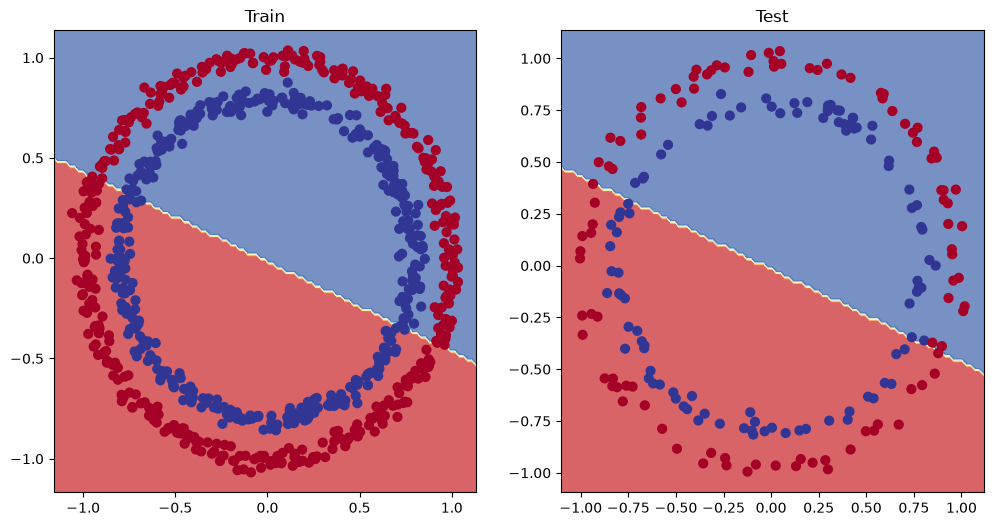

In [25]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

#### Our model is still drawing a straight line between the red and blue dots.



## 5.1 Preparing data to see if our model can model a straight line

In [26]:
# Creating some data 
weight = 0.7
bias = 0.3 

# Creating data 
X_regression = torch.arange(start=0,end=1,step = 0.01).unsqueeze(dim=1)
y_regression = weight * X_regression + bias # Linear Regression Formula 

# Check the Data 
print(len(X_regression))
X_regression[:5],y_regression[:5]



100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [27]:
# Create a Train and test splits 
# from sklearn.model_selection import train_test_split 
# X_train , X_test , y_train , y_test = train_test_split(X,y, test_size=0.2,random_state=19)
train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

# print(len(X_train),len(X_test),len(y_train),len(y_test))
print(len(X_train_regression),len(X_test_regression),len(y_train_regression),len(y_test_regression))

80 20 80 20


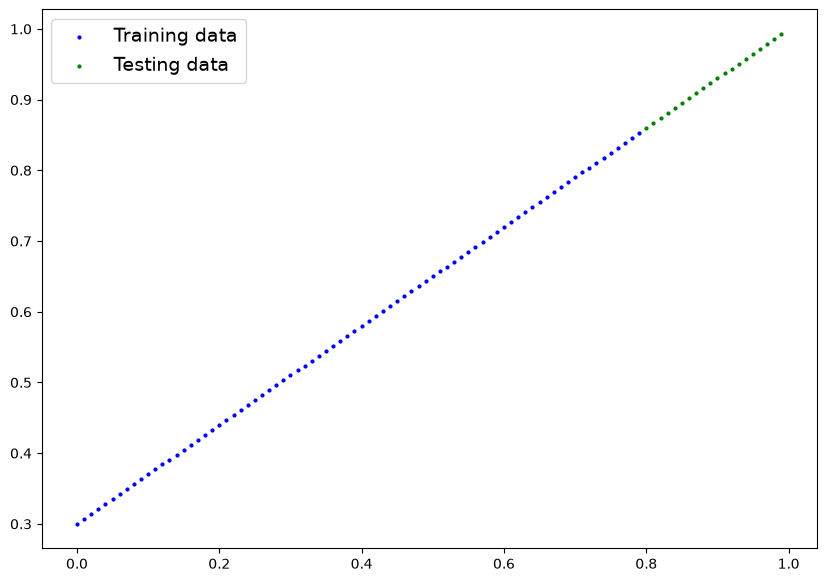

In [28]:
plot_predictions(train_data=X_train_regression,train_labels=y_train_regression,test_data=X_test_regression,test_labels=y_test_regression)


In [29]:
# Create train and test splits
train_split = int(0.8 * len(X_regression)) # 80% of data used for training set
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

# Check the lengths of each split
print(len(X_train_regression), 
    len(y_train_regression), 
    len(X_test_regression), 
    len(y_test_regression))

80 80 20 20


* Before concluding that linear layers cannot solve circles, we must verify that our training code, autograd engine, and optimizer are not broken.

## 5.2 (Model & Training)
* Build a 3-layer linear model (model_2) taking 1 input and returning 1 continuous value.  
* Swap loss to regression loss: loss_fn = nn.L1Loss() (MAE).   Run the training loop. 

In [30]:
# Same architecture as model_1 ( but using nn.sequential)
model_2 = nn.Sequential(
    nn.Linear(in_features=1,out_features=10),
    nn.Linear(in_features=10,out_features=10),
    nn.Linear(in_features=10,out_features=1)
).to(device)

model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

#### We'll setup the loss function to be nn.L1Loss() (the same as mean absolute error) and the optimizer to be torch.optim.SGD()

In [31]:
# Loss and Optimizer 
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(model_2.parameters(),lr=0.1)


##### Now let's train the model using the regular training loop steps for epochs=1000 (just like model_1)

In [32]:
# Train MODEL
torch.manual_seed(19)

# Set the number of epochs 
epochs = 1000

# Put the data in same device 
X_train_regression,y_train_regression = X_train_regression.to(device),y_train_regression.to(device)
X_test_regression,y_test_regression = X_test_regression.to(device),y_test_regression.to(device)

for epochs in range(epochs):

    ###### TRAINING 

    # 1). Forward Pass 
    y_pred = model_2(X_train_regression)

    # 2). calculate Loss ( No need of calculation of accuracy for non classification model)
    loss = loss_fn(y_pred,y_train_regression)

    # 3). optimizer zero grad 
    optimizer.zero_grad()

    # 4). Loss Backward()

    loss.backward()

    # 5). optimizer step 
    optimizer.step()


    ##### TESTING 

    model_2.eval()
    with torch.inference_mode():

        # 1). Forward pass 
        test_pred = model_2(X_test_regression)
        # 2). Calculate Loss 
        test_loss = loss_fn(test_pred,y_test_regression)

    # Print out what's happening
    if epochs % 100 == 0: 
        print(f"Epoch: {epochs} | Train loss: {loss:.5f}, Test loss: {test_loss:.5f}")    

Epoch: 0 | Train loss: 0.62457, Test loss: 0.58417
Epoch: 100 | Train loss: 0.06339, Test loss: 0.22572
Epoch: 200 | Train loss: 0.06066, Test loss: 0.16546
Epoch: 300 | Train loss: 0.06042, Test loss: 0.16377
Epoch: 400 | Train loss: 0.06096, Test loss: 0.13625
Epoch: 500 | Train loss: 0.04994, Test loss: 0.11283
Epoch: 600 | Train loss: 0.05721, Test loss: 0.14588
Epoch: 700 | Train loss: 0.06156, Test loss: 0.14285
Epoch: 800 | Train loss: 0.07011, Test loss: 0.12216
Epoch: 900 | Train loss: 0.04567, Test loss: 0.13687


*  unlike model_1 on the classification data, it looks like model_2's loss is actually going down.

##### Let's plot its predictions to see if that's so

##### And remember, since our model and data are using the target device, and this device may be a GPU, however, our plotting function uses matplotlib and matplotlib can't handle data on the GPU.

##### To handle that, we'll send all of our data to the CPU using .cpu() when we pass it to plot_predictions()

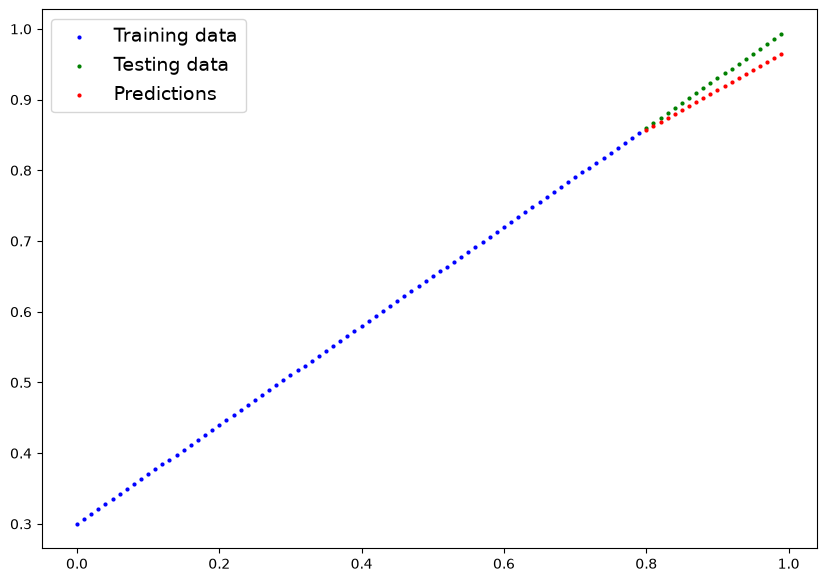

In [33]:
# Turn on evaluation mode 
model_2.eval()

# MAKE PREDICTION INFERENCE 

with torch.inference_mode():
    y_pred = model_2(X_test_regression)
# Plot data and predictions with data on the CPU (matplotlib can't handle data on the GPU)
# (try removing .cpu() from one of the below and see what happens)    

plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_pred.cpu());


#### Alright, it looks like our model is able to do far better than random guessing on straight lines.
#### WE have learn from this section 5.2 is The code, optimizer, and backward passes work properly. The failure on circular data is 100% caused by the geometric inability of linear layers to draw curved boundaries.

# 6. The missing piece: non-linearity

#### We've seen our model can draw straight (linear) lines, thanks to its linear layers.

#### But how about we give it the capacity to draw non-straight (non-linear) lines?

#### How?

### Let's find out.

## 6.1 Recreating non-linear data (red and blue circles)

### First, let's recreate the data to start off fresh. We'll use the same setup as before

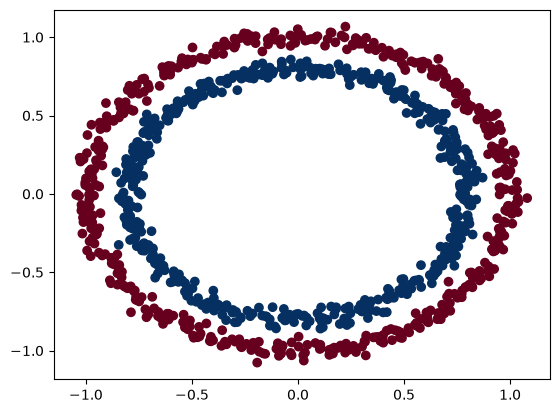

In [34]:
# Make a PLOT Data 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_circles

n_samples = 1000 

X,y = make_circles(n_samples= 1000, noise= 0.03 , random_state= 19)
plt.scatter(X[:,0],X[:,1], c = y ,cmap = plt.cm.RdBu) 

In [35]:
# Convert to tensors and split into train and test sets
import torch 
from sklearn.model_selection import train_test_split 

# Convert data into tensor 

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# Split into train and test sets

X_train ,X_test , y_train , y_test = train_test_split(X,y,test_size= 0.2, random_state= 19)
X_train[:5],y_train[:5]

(tensor([[ 0.3679, -0.9140],
         [ 0.4226,  0.7074],
         [ 0.5799, -0.4547],
         [ 0.8977,  0.3727],
         [-0.3419, -0.7237]]),
 tensor([0., 1., 1., 0., 1.]))

## 6.2 Building a model with non-linearity

##### PyTorch has a bunch of ready-made non-linear activation functions that do similar but different things.
##### One of the most common and best performing is ReLU (rectified linear-unit, torch.nn.ReLU())

In [36]:
# Build model with non-linear activation function
import torch
from torch import nn
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2,out_features=10)
        self.layer_2 = nn.Linear(in_features=10,out_features=10)
        self.layer_3 = nn.Linear(in_features=10,out_features=1)
        self.relu = nn.ReLU() #  add in ReLU activation function



    def forward(self, x):
         # Intersperse the ReLU activation function between layers
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))  

model_3 = CircleModelV2().to(device)

print(model_3)  

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)


#### Now we've got a model ready to go, let's create a binary classification loss function as well as an optimizer

In [37]:
# SET Loss and optimizer 
Loss = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(),lr = 0.1 )

## 6.3 Training a model with non-linearity

#### To observe how gradient descent optimizes non-linear decision surfaces compared to linear ones

In [38]:
# Fit Model 
torch.manual_seed(19)
epochs = 1000

# Put all data on taget device 
X_train , y_train = X_train.to(device),y_train.to(device)
X_test , y_test =   X_test.to(device),y_test.to(device)

for epochs in range(epochs):
    ## 1). Forward pass 
    y_logits = model_3(X_train).squeeze()
    y_preds = torch.round(torch.sigmoid(y_logits))

    ## 2). Calculation Loss and Accuracy 
    loss = loss_fn(y_logits,y_train) # BCEWithLogitsLoss calculates loss using logits
    acc = accuracy_fn(y_true=y_train,y_pred=y_preds)

    ## 3). Optimizer Zero 
    optimizer.zero_grad()

    ## 4). loss backward 
    loss.backward()

    ## 5). optimizer step 
    optimizer.step()

    #### TESTING 
    model_3.eval()

    with torch.inference_mode():

        ## 1). Forward pass 
        test_logits = model_3(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        ## 2). Caluclate loss and accuracy 

        test_loss = loss_fn(test_logits,y_test)
        test_acc = accuracy_fn(y_true=y_test,y_pred=test_pred)
# Print out what's happening
    if epochs % 100 == 0:
        print(f"Epoch: {epochs} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")






Epoch: 0 | Loss: 0.49866, Accuracy: 49.88% | Test Loss: 0.50511, Test Accuracy: 50.50%
Epoch: 100 | Loss: 0.48724, Accuracy: 50.75% | Test Loss: 0.49191, Test Accuracy: 51.50%
Epoch: 200 | Loss: 0.46716, Accuracy: 51.00% | Test Loss: 0.47366, Test Accuracy: 52.00%
Epoch: 300 | Loss: 0.41830, Accuracy: 51.50% | Test Loss: 0.42552, Test Accuracy: 52.00%
Epoch: 400 | Loss: 0.33479, Accuracy: 54.37% | Test Loss: 0.33482, Test Accuracy: 53.00%
Epoch: 500 | Loss: 0.27337, Accuracy: 75.25% | Test Loss: 0.29136, Test Accuracy: 50.50%
Epoch: 600 | Loss: 0.19539, Accuracy: 66.12% | Test Loss: 0.19928, Test Accuracy: 50.50%
Epoch: 700 | Loss: 0.19069, Accuracy: 74.50% | Test Loss: 0.19001, Test Accuracy: 50.50%
Epoch: 800 | Loss: 0.14946, Accuracy: 78.75% | Test Loss: 0.21396, Test Accuracy: 50.50%
Epoch: 900 | Loss: 0.15142, Accuracy: 73.62% | Test Loss: 0.13870, Test Accuracy: 54.50%


In [39]:
# Make predictions
model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_preds[:10], y[:10] # want preds in same format as truth labels

(tensor([1., 1., 0., 1., 1., 1., 1., 1., 0., 0.], device='mps:0'),
 tensor([1., 1., 0., 1., 0., 1., 0., 1., 1., 0.]))

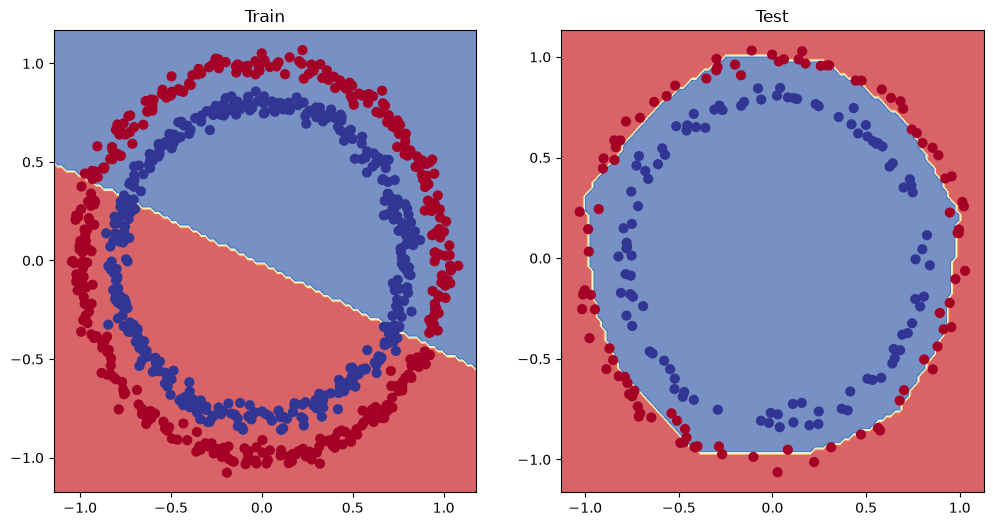

In [40]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train) # model_1 = no non-linearity
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test) # model_3 = has non-linearity

# 7. Replicating non-linear activation functions
#### Before moving to multi-class classification, you must know how the main activation functions work mathematically and how to code them from scratch in pure PyTorch.

In [41]:
## Create a Toy tensor 

A = torch.arange(-10,10,1,dtype=torch.float32)


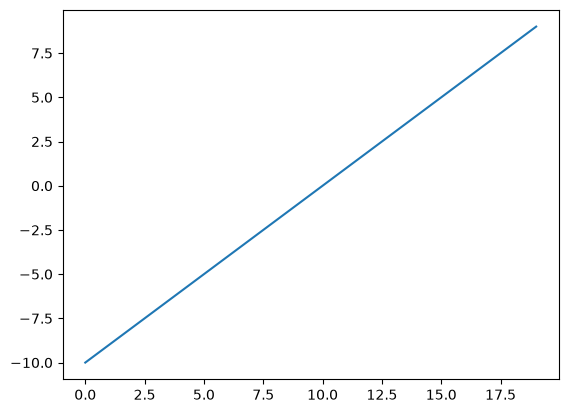

In [42]:
plt.plot(A)

* A straight line, nice.

* Now let's see how the ReLU activation function influences it.

* And instead of using PyTorch's ReLU (torch.nn.ReLU), we'll recreate it ourselves.

* The ReLU function turns all negatives to 0 and leaves the positive values as they are.

In [43]:
# Create a Relu function from scratch 

def relu(X):
    return torch.maximum(torch.tensor(0),X) # Input must be a tensor 

# Pass toy tensor through RELU Function 
relu(A)


tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])


* It looks like our ReLU function worked, all of the negative values are zeros.

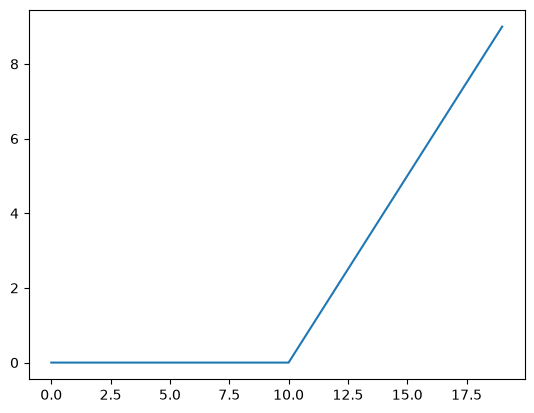

In [45]:
plt.plot(relu(A))

##### Let's build a function to replicate the sigmoid function with PyTorch

In [46]:
## Create a custom sigmoid function 

def sigmoid(X):
    return 1 / (1+torch.exp(-X))

# Test custom sigmoid on toy tensor 
sigmoid(A)

tensor([4.5398e-05, 1.2339e-04, 3.3535e-04, 9.1105e-04, 2.4726e-03, 6.6929e-03,
        1.7986e-02, 4.7426e-02, 1.1920e-01, 2.6894e-01, 5.0000e-01, 7.3106e-01,
        8.8080e-01, 9.5257e-01, 9.8201e-01, 9.9331e-01, 9.9753e-01, 9.9909e-01,
        9.9966e-01, 9.9988e-01])

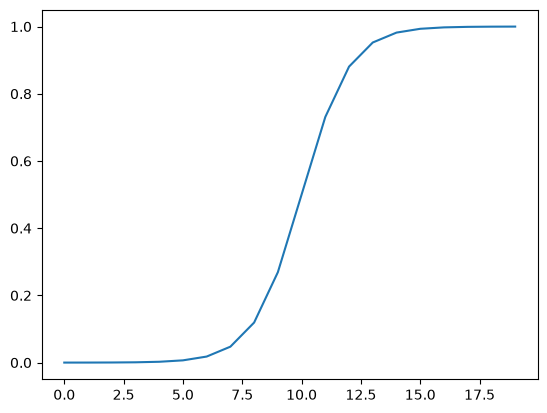

In [47]:
plt.plot(sigmoid(A))

# 8. Putting things together by building a multi-class PyTorch model

##### To begin a multi-class classification problem, let's create some multi-class data.

##### To do so, we can leverage Scikit-Learn's make_blobs() method.

##### This method will create however many classes (using the centers parameter) we want.

### Specifically, let's do the following:

##### 1).Create some multi-class data with make_blobs().
##### 2). Turn the data into tensors (the default of make_blobs() is to use NumPy arrays).
##### 3).Split the data into training and test sets using train_test_split().
##### 4). Visualize the data.

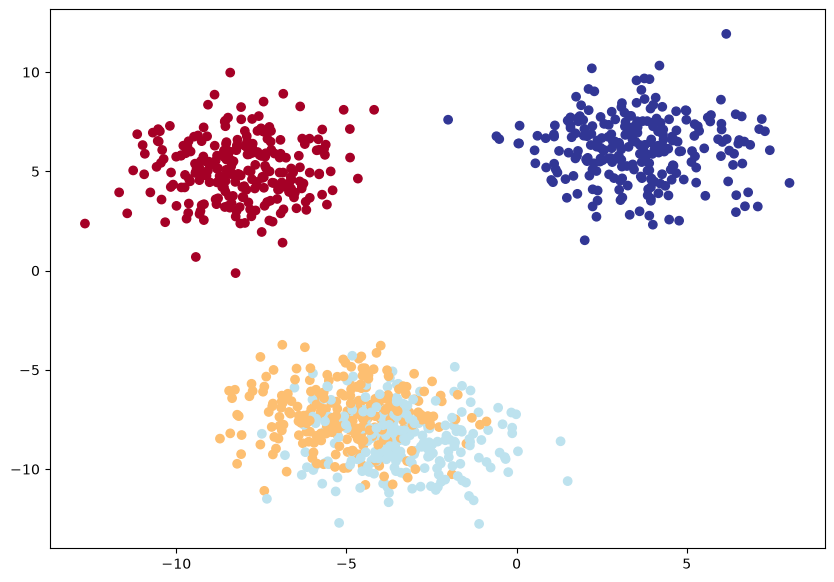

In [49]:

import torch 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters for data creation

NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 19

#### 1)> Create a multi-class data 
X_blobs,y_blobs = make_blobs(n_samples=1000,
                             n_features=NUM_FEATURES, # X Features 
                             centers=NUM_CLASSES, # y labels 
                             cluster_std=1.5,     # gives cluster little shake up 
                             random_state=RANDOM_SEED)

#### 2 ). turn the data into tensor 
X_blobs = torch.from_numpy(X_blobs).type(torch.float)
y_blobs = torch.from_numpy(y_blobs).type(torch.LongTensor)

#### 3 ). Split the data into training set and test set
X_blobs_train , x_blobs_test , y_blobs_train , y_blobs_test = train_test_split(X_blobs,y_blobs,test_size=0.2,random_state=19)

#### 4 ). plot Data 

plt.figure(figsize=(10,7))
plt.scatter(X_blobs[:,0],X_blobs[:,1], c=y_blobs,cmap= plt.cm.RdYlBu);



* Let's build a model to separate the coloured blobs

## 8.2 Building a multi-class classification model in PyTorch

In [50]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device = torch.device(device)
print(f"Using device: {device}")


Using device: mps


In [ ]:
from torch.nn
